# Supplementary figure - Analysis of the data-driven model (BRCA/CRC versus healthy) and ranking functions (both tasks)

Six panels combining panels of `fig5.ipynb` and `figS4.ipynb` (code copied from those notebooks, whose
own figures this notebook does not write):
- (a) AUROC against the number of selected TSSs (k) per fragmentomic feature, BRCA/CRC versus healthy;
- (b) the same per classifier;
- (c) label permutation: pooled out-of-fold ROC of the fully nested procedure with true and permuted
  labels, both tasks;
- (d) AUROC by aggregation level (all TSSs pooled, 39 chromosome arms, 50 Hallmark gene sets; pooled
  profile filled, averaged per-TSS values open), BRCA/CRC versus healthy;
- (e, f) AUROC against k per ranking function, BRCA/CRC and pan-cancer versus healthy.

In a, b, e and f solid lines are the best configuration at each k and dashed lines the mean over
configurations; this sweep is descriptive (configurations scored on the outer test folds). The
dash-dotted line is the fully nested AUROC.

Source data (`data/no_deep/`): `fig5_auc_sweep.csv`, `fig5c_resolution.csv`, `fig5_status.csv` from
`export/export_fig5.py`; `figS5_nested_runs.csv`, `figS5_nested_oof.csv` from `export/export_figS5_nested.py`.

Output: `output/no_deep/figS_model_analysis.png` (600 dpi) and `.pdf`, in the shared figure style (`_figstyle.py`).

In [1]:
import os

# Data paths are relative to src/figures/; change there if the kernel started elsewhere.
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# Cohort: "no_deep" (default; without the 30 deep-sequenced healthy controls, data/no_deep/) or
# "all" (full cohort, data/). Set here or via FIG_COHORT. Missing files fall back to data/.
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib as mpl
import _figstyle as fs
fs.apply()

# --- from fig5.ipynb ---------------------------------------------------------------
# Keys must match the `classifier` values in fig5_auc_sweep.csv exactly.
CLASSIFIER_COLORS = {
    "K-Nearest Neighbors": "#0173B2", "Logistic Regression": "#DE8F05",
    "Multi-Layer Perceptron": "#029E73", "Random Forest": "#CC78BC",
    "Support Vector Machine": "#CA3542", "XGBoost": "#CA9161",
}
FEATURE_COLORS = {f: fs.FEATURE[n] for f, n in {"fslr": "FSLR", "fslr_coverage": "FSLRC", "griffin_diff": "GD",
                                               "rcov": "RCOV", "mwh": "MWH"}.items()}
FEATURE_NAME_MAP = {"fslr": "FSLR", "fslr_coverage": "FSLRC", "griffin_diff": "GD",
                    "rcov": "RCOV", "mwh": "MWH"}
CLASSIFIER_NAME_MAP = {"K-Nearest Neighbors": "KNN", "Logistic Regression": "LR",
                       "Multi-Layer Perceptron": "MLP", "Random Forest": "RF",
                       "Support Vector Machine": "SVM", "XGBoost": "XGB"}

# --- from figS4.ipynb --------------------------------------------------------------
WEIGHTING_COLORS = {
    "fold_change": "#56B4E9", "mean_diff": "#E69F00", "p_value": "#009E73",
    "random": "#999999", "weighted": "#D55E00",
}
WEIGHTING_NAME_MAP = {
    "fold_change": "log-FC", "mean_diff": "|Δμ|", "p_value": "MWU",
    "random": "random", "weighted": "weighted",
}

# --- this notebook -----------------------------------------------------------------
# Task names as printed in the figure.
TASKS = [("brca_crc", "BRCA/CRC versus healthy"), ("pancan", "Pan-cancer versus healthy")]
TASK_NAMES = dict(TASKS)
STEM = "figS_model_analysis"

# Font sizes (points) from the shared figure style; the figure is drawn at its printed size (180 mm wide).
FS = {"label": fs.FONT, "tick": fs.SMALL, "legend": fs.SMALL, "note": fs.VALUE, "letter": fs.LETTER, "title": fs.FONT + 0.5}
LEGEND_ROW_SPACING = 0.3

# Modification times of the source notebooks' figures; the last cell checks they did not change.
_SOURCE_FIGURES = [out_path(f"{stem}.{ext}") for stem in ("fig5", "figS_model_brca_crc", "figS4")
                   for ext in ("png", "pdf")]
_SOURCE_MTIMES = {p: os.path.getmtime(p) for p in _SOURCE_FIGURES if os.path.exists(p)}

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


In [2]:
sweep = pd.read_csv(data_path("fig5_auc_sweep.csv"))
res = pd.read_csv(data_path("fig5c_resolution.csv"))
status = pd.read_csv(data_path("fig5_status.csv"))
perm_runs = pd.read_csv(data_path("figS5_nested_runs.csv"))
perm_oof = pd.read_csv(data_path("figS5_nested_oof.csv"))
if "complete" not in perm_runs:
    perm_runs["complete"] = True
perm_runs["complete"] = perm_runs["complete"].fillna(True).astype(bool)
summary = (sweep.groupby(["task", "feature", "classifier", "weighting_function", "top_genes"])["auc"]
           .mean().rename("mean_full_auc").reset_index().rename(columns={"top_genes": "n_genes"}))
NESTED = res[res["level"] == "individual TSSs"].set_index("task")["auc_fold_mean"].to_dict()
print(status.groupby(["task", "state"]).size().rename("sources").to_string())
for task, name in TASKS:
    s = summary[summary["task"] == task]
    print(f"{name} ({task}): {s.groupby(['feature','classifier','weighting_function','n_genes']).ngroups} configurations in the sweep; "
          f"fully nested AUROC {NESTED[task]:.3f}" + (f"; best configuration (descriptive) {s['mean_full_auc'].max():.3f}" if len(s) else ""))

task      state   
brca_crc  complete    6
pancan    complete    6
BRCA/CRC versus healthy (brca_crc): 1800 configurations in the sweep; fully nested AUROC 0.966; best configuration (descriptive) 0.975
Pan-cancer versus healthy (pancan): 1800 configurations in the sweep; fully nested AUROC 0.969; best configuration (descriptive) 0.970


## Panels a and b - AUROC against the number of TSSs, per feature and per classifier

In [3]:
def _style_axis(ax):
    ax.set_xscale("log")
    ax.set_ylim(0.55, 1.0)
    fs.value_grid(ax)


def legend_below(ax, handles, labels, ncol, drop=24, **kw):
    """Legend centred under the axes, `drop` points below the bottom spine (clear of tick labels and axis label)."""
    shift = mpl.transforms.ScaledTranslation(0, -drop / 72, ax.get_figure(root=True).dpi_scale_trans)
    return ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0), bbox_transform=ax.transAxes + shift,
                     ncol=ncol, borderaxespad=0, columnspacing=1.2, **kw)


def nested_line(ax, nested):
    """Dash-dotted line at the fully nested AUROC with its value (6 pt, white halo where it crosses the grid)."""
    ax.axhline(nested, color="black", linestyle="-.", linewidth=0.8, alpha=0.8, zorder=1)
    ax.text(ax.get_xlim()[0] * 1.12, nested + 0.006, f"fully nested model: {nested:.3f}", ha="left", va="bottom",
            fontsize=FS["note"], bbox=dict(boxstyle="square,pad=0.1", facecolor="white", edgecolor="none", alpha=0.85), zorder=4)


def panel_sweep(ax, task, group_col, colors, name_map, ncol=3):
    s = summary[summary["task"] == task]
    nested = NESTED[task]
    if not len(s):
        ax.text(0.5, 0.5, "per-configuration sweep pending\n(slurm/nested_cv_dd.sh, no_deep)", transform=ax.transAxes,
                ha="center", va="center", fontsize=FS["label"], color="0.4")
        _style_axis(ax)
        ax.set_xlim(8, 20000)
    else:
        order = [k for k in colors if k in set(s[group_col])]   # fixed legend order
        for key in order:
            agg = s[s[group_col] == key].groupby("n_genes")["mean_full_auc"].agg(["max", "mean"])
            color = colors.get(key, "#999999")
            ax.plot(agg.index, agg["max"], marker="o", markersize=2.5, linewidth=1.1, color=color, zorder=3,
                    label=name_map.get(key, key))
            ax.plot(agg.index, agg["mean"], linestyle="--", linewidth=0.7, color=color, alpha=0.5, zorder=2)
        _style_axis(ax)
    nested_line(ax, nested)
    ax.set_xlabel("Number of selected TSSs (k)")
    ax.set_ylabel("AUROC (mean over outer folds)")
    if len(s):
        h, l = ax.get_legend_handles_labels()
        legend_below(ax, h, l, ncol=ncol, labelspacing=LEGEND_ROW_SPACING)


## Panels c and d - label permutation, AUROC by aggregation level

In [4]:
LEVELS = [("genome-wide", "All TSSs\npooled"), ("chromosome arms", "Chromosome\narms (39)"),
          ("Hallmark gene sets", "Hallmark gene\nsets (50)")]
FEAT_ORDER = ["griffin_diff", "fslr", "fslr_coverage", "rcov", "mwh"]


def panel_resolution(ax, task):
    r = res[res["task"] == task]
    offs = dict(zip(FEAT_ORDER, np.linspace(-0.32, 0.32, len(FEAT_ORDER))))
    for xi, (level, _) in enumerate(LEVELS):
        for f in FEAT_ORDER:
            for mode, dx, face in [("pooled", -0.04, None), ("averaged", 0.04, "white")]:
                g = r[(r["level"] == level) & (r["feature"] == f) & (r["mode"] == mode)]
                if not len(g):
                    continue
                c = FEATURE_COLORS[f]
                x = xi + offs[f] + dx
                ax.errorbar(x, g["auc_fold_mean"].iloc[0], yerr=g["auc_fold_sd"].iloc[0], fmt="o", markersize=3,
                            color=c, markerfacecolor=face or c, markeredgecolor=c, markeredgewidth=0.8,
                            elinewidth=0.7, capsize=0, alpha=0.95, zorder=3)
        if level == "genome-wide" and len(r[r["level"] == level]) < len(FEAT_ORDER):
            ax.text(xi, 0.42, f"{len(r[r['level'] == level])}/5 features\n(rest pending)", ha="center", fontsize=FS["legend"], color="0.4")
    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8)
    for xi in range(len(LEVELS) - 1):
        ax.axvline(xi + 0.5, color="0.88", linewidth=0.6, zorder=0)
    ax.set_xticks(range(len(LEVELS)))
    ax.set_xticklabels([lab for _, lab in LEVELS])
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.5, len(LEVELS) - 0.5)
    ax.set_ylim(0.3, 1.0)
    ax.set_ylabel("AUROC (mean over outer folds $\\pm$ SD)")
    fs.value_grid(ax)
    # the feature colours are those of panel a (legend under a); this legend gives the two marker styles
    h = [Line2D([], [], marker="o", ls="none", color="0.35", markersize=3, label="Pooled profile"),
         Line2D([], [], marker="o", ls="none", color="0.35", markerfacecolor="white", markeredgewidth=0.8, markersize=3,
                label="Averaged per-TSS values")]
    ax.legend(handles=h, loc="upper left", handletextpad=0.3, labelspacing=LEGEND_ROW_SPACING)


from sklearn.metrics import roc_curve

C_TRUE, C_PERM = fs.METHOD["Data-driven"], "0.45"


def panel_permutation(ax, task):
    """Pooled out-of-fold ROC of the fully nested procedure: true labels vs permuted labels (True if a draft)."""
    r = perm_runs[perm_runs["task"] == task].set_index("run")
    perms = [p for p in r.index if p != "true_labels"]
    for run in perms:
        d = perm_oof[(perm_oof["task"] == task) & (perm_oof["run"] == run)]
        fpr, tpr, _ = roc_curve(d["y_true"], d["score"])
        note = "" if r.loc[run, "complete"] else f", {int(r.loc[run, 'n_folds'])}/10 folds"
        ax.plot(fpr, tpr, color=C_PERM, lw=1.0, alpha=0.9, zorder=2,
                label=f"Permuted labels: {r.loc[run, 'auc_fold_mean']:.2f}{note}" if run == perms[0] else None)
    d = perm_oof[(perm_oof["task"] == task) & (perm_oof["run"] == "true_labels")]
    fpr, tpr, _ = roc_curve(d["y_true"], d["score"])
    ax.plot(fpr, tpr, color=C_TRUE, lw=1.4, zorder=3, label=f"True labels: {r.loc['true_labels', 'auc_fold_mean']:.3f}")
    ax.plot([0, 1], [0, 1], color=fs.CHANCE, ls=":", lw=0.8, zorder=1)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_aspect("equal")
    ax.set_anchor("N")   # square panel at the top of its slot: title in line with the other panels
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    h, l = ax.get_legend_handles_labels()
    order = sorted(range(len(l)), key=lambda i: not l[i].startswith("True"))
    ax.legend([h[i] for i in order], [l[i] for i in order], loc="lower right", title="AUROC (mean over\nouter folds)",
              alignment="left", labelspacing=LEGEND_ROW_SPACING)
    return not all(r.loc[p, "complete"] for p in perms)


def panel_permutation_both(ax):
    """Pooled out-of-fold ROC of the fully nested procedure for both tasks, true labels (solid) and
    labels permuted once before the outer folds (dashed); task colours of the shared style. True if a draft."""
    draft = False
    handles, labels = [], []
    for task, name in TASKS:
        r = perm_runs[perm_runs["task"] == task].set_index("run")
        color = fs.TASK[name]
        d = perm_oof[(perm_oof["task"] == task) & (perm_oof["run"] == "true_labels")]
        fpr, tpr, _ = roc_curve(d["y_true"], d["score"])
        h, = ax.plot(fpr, tpr, color=color, lw=1.3, zorder=3)
        handles.append(h); labels.append(f"{name.split(' versus')[0]}, true: {r.loc['true_labels', 'auc_fold_mean']:.3f}")
        for run in [x for x in r.index if x != "true_labels"]:
            d = perm_oof[(perm_oof["task"] == task) & (perm_oof["run"] == run)]
            fpr, tpr, _ = roc_curve(d["y_true"], d["score"])
            h, = ax.plot(fpr, tpr, color=color, lw=0.9, ls="--", alpha=0.9, zorder=2)
            if run == "perm1":
                handles.append(h); labels.append(f"{name.split(' versus')[0]}, permuted: {r.loc[run, 'auc_fold_mean']:.2f}")
            draft = draft or not r.loc[run, "complete"]
    ax.plot([0, 1], [0, 1], color=fs.CHANCE, ls=":", lw=0.8, zorder=1)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_aspect("equal")
    ax.set_anchor("N")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(handles, labels, loc="lower right", title="AUROC (mean over folds)", alignment="left",
              labelspacing=LEGEND_ROW_SPACING, handlelength=1.6, frameon=True, facecolor="white", edgecolor="none",
              framealpha=0.95, borderpad=0.3, borderaxespad=0.2)
    return draft


## Panels e and f - AUROC against the number of TSSs, per ranking function

In [5]:
RANKING_ORDER = ["mean_diff", "p_value", "weighted", "fold_change", "random"]


def panel_ranking(ax, task):
    s = summary[summary["task"] == task]
    order = [w for w in RANKING_ORDER if w in set(s["weighting_function"])]
    for w in order:
        agg = s[s["weighting_function"] == w].groupby("n_genes")["mean_full_auc"].agg(["max", "mean"])
        color = WEIGHTING_COLORS.get(w, "#999999")
        ax.plot(agg.index, agg["max"], marker="^", markersize=3, linewidth=1.1, color=color, zorder=3,
                label=WEIGHTING_NAME_MAP.get(w, w))
        ax.plot(agg.index, agg["mean"], linestyle="--", linewidth=0.7, color=color, alpha=0.5, zorder=2)
    ax.set_xscale("log")
    nested_line(ax, NESTED[task])
    ax.set_ylim(0.5, 1.0)
    ax.set_xlabel("Number of selected TSSs (k)")
    fs.value_grid(ax)


## Assemble the figure

Rows a-c and d-f; the legends of the ranking functions and line styles in a strip under the figure.

saved output\no_deep\figS_model_analysis.png/.pdf at 178 x 152 mm


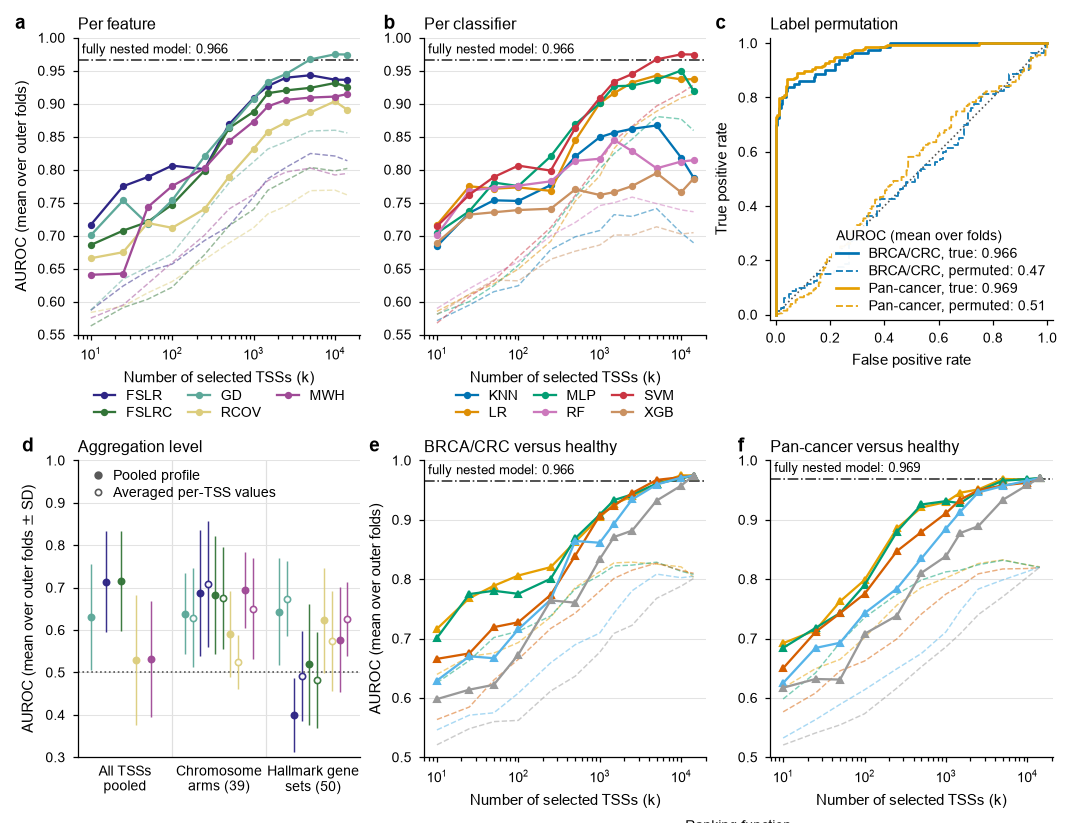

In [6]:
# Drawn at print size (180 mm wide) in the shared style (_figstyle.py). Rows: a-c, d-f (caption order).
# The bottom strip holds the legend of the ranking functions (e, f) and of the line styles (a, b, e, f).
fig = plt.figure(figsize=fs.size(height=6.0), layout="constrained")
BOTTOM = 0.105                                  # figure fraction kept free for the bottom legends
fig.get_layout_engine().set(rect=(0, BOTTOM, 1, 1 - BOTTOM))
gs = fig.add_gridspec(2, 3)
ax_a, ax_b, ax_c = (fig.add_subplot(gs[0, i]) for i in range(3))
ax_d = fig.add_subplot(gs[1, 0])
ax_e = fig.add_subplot(gs[1, 1])
ax_f = fig.add_subplot(gs[1, 2], sharey=ax_e)
PANELS = {"a": ax_a, "b": ax_b, "c": ax_c, "d": ax_d, "e": ax_e, "f": ax_f}

# top row: BRCA/CRC versus healthy (draw_task of fig5.ipynb; the caption names the task)
panel_sweep(ax_a, "brca_crc", "feature", FEATURE_COLORS, FEATURE_NAME_MAP)
panel_sweep(ax_b, "brca_crc", "classifier", CLASSIFIER_COLORS, CLASSIFIER_NAME_MAP)
ax_b.set_ylabel("")                             # same quantity and limits as a
DRAFT = panel_permutation_both(ax_c)   # both tasks
panel_resolution(ax_d, "brca_crc")

# bottom row: ranking functions, one panel per task (figS4.ipynb)
panel_ranking(ax_e, "brca_crc")
panel_ranking(ax_f, "pancan")
ax_e.set_ylabel("AUROC (mean over outer folds)")
ax_f.tick_params(labelleft=True)                # tick labels on both: the letter stays clear of the title

for letter, title in [("a", "Per feature"), ("b", "Per classifier"), ("c", "Label permutation"),
                      ("d", "Aggregation level"), ("e", TASK_NAMES["brca_crc"]), ("f", TASK_NAMES["pancan"])]:
    fs.panel(PANELS[letter], letter, title)

# bottom legends, centred under e and f once the layout is final
fig.canvas.draw()
pe, pf = ax_e.get_position(), ax_f.get_position()
xc = (pe.x0 + pf.x1) / 2
h, l = ax_e.get_legend_handles_labels()
leg_rank = fig.legend(h, l, loc="upper center", bbox_to_anchor=(xc, BOTTOM - 0.002), ncol=len(l), title="Ranking function",
                      columnspacing=1.4, borderaxespad=0, frameon=False)
style = [Line2D([0], [0], color="0.3", linewidth=1.1, marker="o", markersize=2.5),
         Line2D([0], [0], color="0.3", linewidth=0.7, linestyle="--", alpha=0.6),
         Line2D([0], [0], color="black", linewidth=0.8, linestyle="-.", alpha=0.8)]
leg_style = fig.legend(style, ["Best configuration", "Mean of configurations", "Fully nested model"], loc="lower center",
                       bbox_to_anchor=(0.5, 0.004), ncol=3, columnspacing=1.4, borderaxespad=0, frameon=False,
                       title="Lines in a, b, e and f")
for leg in (leg_rank, leg_style):
    leg.set_in_layout(False)

stem = STEM + ("_draft" if DRAFT else "")   # an unaggregated permutation run never overwrites the final figure
WRITTEN = [out_path(f"{stem}.png"), out_path(f"{stem}.pdf")]
fs.save(fig, out_path(stem))
plt.show()

## Checks

Printed nested values, panel order, figure text, curves and permutation legend against the source data,
the output files, and that the source notebooks' figures are unchanged.

In [7]:
import re
from matplotlib.text import Text
from PIL import Image

# 1. fully nested AUROC printed in the panels: 0.966 (BRCA/CRC versus healthy: a, b, e), 0.969 (pan-cancer: f)
assert f"{NESTED['brca_crc']:.3f}" == "0.966" and f"{NESTED['pancan']:.3f}" == "0.969", NESTED
printed = {letter: [t.get_text() for t in ax.texts if t.get_text().startswith("fully nested model")]
           for letter, ax in PANELS.items()}
expected = {"a": ["fully nested model: 0.966"], "b": ["fully nested model: 0.966"], "c": [], "d": [],
            "e": ["fully nested model: 0.966"], "f": ["fully nested model: 0.969"]}
assert printed == expected, printed
print("fully nested values printed:", {k: v[0].split(": ")[1] for k, v in printed.items() if v})

# 2. letters a-f in reading order: a-c left to right in the top row, d-f left to right below (print layout)
pos = {letter: ax.get_position() for letter, ax in PANELS.items()}
assert pos["a"].x0 < pos["b"].x0 < pos["c"].x0 and pos["d"].x0 < pos["e"].x0 < pos["f"].x0
assert min(pos[l].y0 for l in "abc") > max(pos[l].y1 for l in "def")
for letter, ax in PANELS.items():
    assert [t.get_text() for t in ax.texts if t.get_fontweight() == "bold"] == [letter], letter
print("panel letters in reading order:", " ".join(PANELS))

# 3. task names and wording of every text in the figure
texts = sorted({t.get_text() for t in fig.findobj(Text) if t.get_text().strip()})
titles = {"top row": [t.get_text() for t in ax_a.texts if "versus" in t.get_text()],
          "e": [ax_e.get_title(loc="left")], "f": [ax_f.get_title(loc="left")]}
assert titles == {"top row": [], "e": ["BRCA/CRC versus healthy"],
                  "f": ["Pan-cancer versus healthy"]}, titles
for t in texts:
    assert "PANCAN" not in t and not re.search(r"\bvs\b|\bAUC\b|pancan|Healthy versus", t), t
print("titles:", titles)

# 4. the curves are the source data: number of drawn lines and the solid curves against the sweep
def solid_curves(ax):
    return {l.get_label(): l for l in ax.lines if l.get_linestyle() == "-" and not l.get_label().startswith("_")}

for letter, task, col, names in [("a", "brca_crc", "feature", FEATURE_NAME_MAP), ("b", "brca_crc", "classifier", CLASSIFIER_NAME_MAP),
                                 ("e", "brca_crc", "weighting_function", WEIGHTING_NAME_MAP),
                                 ("f", "pancan", "weighting_function", WEIGHTING_NAME_MAP)]:
    s = sweep[sweep["task"] == task]
    per_config = s.groupby([col, "feature", "classifier", "weighting_function", "top_genes"])["auc"].mean()
    best = per_config.groupby(level=[0, 4]).max()          # level 0 = the grouping column, level 4 = k
    curves = solid_curves(PANELS[letter])
    assert set(curves) == {names[k] for k in s[col].unique()}, (letter, set(curves))
    assert len(PANELS[letter].lines) == 2 * len(curves) + 1   # solid + dashed per group, and the nested line
    for key, name in names.items():
        assert np.allclose(curves[name].get_ydata(), best.loc[key].sort_index().to_numpy()), (letter, name)
        assert list(curves[name].get_xdata()) == sorted(s["top_genes"].unique()), (letter, name)
    print(f"panel {letter}: {len(curves)} groups x {len(sorted(s['top_genes'].unique()))} values of k, "
          f"best configuration {best.max():.3f}")
n_points = len(res[(res["task"] == "brca_crc") & (res["level"] != "individual TSSs") & res["feature"].isin(FEAT_ORDER)])
assert len(ax_d.containers) == n_points == 25, (len(ax_d.containers), n_points)
_leg = [l.get_text() for l in ax_c.get_legend().get_texts()]
for task, name in TASKS:
    r = perm_runs[perm_runs["task"] == task].set_index("run")
    assert f"{name.split(' versus')[0]}, true: {r.loc['true_labels', 'auc_fold_mean']:.3f}" in _leg, (task, _leg)
assert len(_leg) == 4, _leg
print("panel c:", [l.get_text() for l in ax_c.get_legend().get_texts()])
print(f"panel d: {n_points} points (5 features: 5 genome-wide, 10 chromosome arms, 10 Hallmark)")

# 5. output files, and the figures of the source notebooks untouched
for p in WRITTEN:
    assert os.path.exists(p) and os.path.getsize(p) > 10_000, p
with Image.open(WRITTEN[0]) as im:
    dpi = tuple(round(float(d)) for d in im.info["dpi"])
    assert dpi == (600, 600), dpi
    print(f"{WRITTEN[0]}: {im.size[0]} x {im.size[1]} px at {dpi[0]} dpi "
          f"({im.size[0] / dpi[0]:.1f} x {im.size[1] / dpi[1]:.1f} in)")
print(f"{WRITTEN[1]}: {os.path.getsize(WRITTEN[1]) / 1024:.0f} kB")
assert [os.path.basename(p) for p in WRITTEN] == [f"{stem}.png", f"{stem}.pdf"]
changed = [p for p, m in _SOURCE_MTIMES.items() if os.path.getmtime(p) != m]
assert not changed, changed
print(f"source figures untouched: {len(_SOURCE_MTIMES)} files checked")
print("all checks passed")

fully nested values printed: {'a': '0.966', 'b': '0.966', 'e': '0.966', 'f': '0.969'}
panel letters in reading order: a b c d e f
titles: {'top row': [], 'e': ['BRCA/CRC versus healthy'], 'f': ['Pan-cancer versus healthy']}
panel a: 5 groups x 12 values of k, best configuration 0.975
panel b: 6 groups x 12 values of k, best configuration 0.975
panel e: 5 groups x 12 values of k, best configuration 0.975
panel f: 5 groups x 12 values of k, best configuration 0.970
panel c: ['BRCA/CRC, true: 0.966', 'BRCA/CRC, permuted: 0.47', 'Pan-cancer, true: 0.969', 'Pan-cancer, permuted: 0.51']
panel d: 25 points (5 features: 5 genome-wide, 10 chromosome arms, 10 Hallmark)
output\no_deep\figS_model_analysis.png: 4204 x 3600 px at 600 dpi (7.0 x 6.0 in)
output\no_deep\figS_model_analysis.pdf: 79 kB
source figures untouched: 4 files checked
all checks passed
